In [1]:
import pandas as pd

# Membaca file CSV
data = pd.read_csv('dataset_sms_spam_v2.csv')

# Menampilkan 5 baris pertama untuk melihat struktur data
print(data.head())

                                                Teks  label
0  [PROMO] Beli paket Flash mulai 1GB di MY TELKO...  promo
1  2.5 GB/30 hari hanya Rp 35 Ribu Spesial buat A...  promo
2  2016-07-08 11:47:11.Plg Yth, sisa kuota Flash ...  promo
3  2016-08-07 11:29:47.Plg Yth, sisa kuota Flash ...  promo
4  4.5GB/30 hari hanya Rp 55 Ribu Spesial buat an...  promo


In [2]:
# Memisahkan fitur dan label
X = data['Teks'] # Pesan SMS
y = data['label'] # Label (normal, penipuan, atau promo)

In [3]:
from sklearn.model_selection import train_test_split

# Membagi dataset menjadi data latih (80%) dan uji (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [4]:
import re
import nltk
from nltk.corpus import stopwords
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

# Preprocessing function
def preprocess_text(text):
    #Mengubah teks menjadi huruf kecil
    text = text.lower()
    # Menghapus karakter yang tidak perlu (tanda baca, angka, dll)
    text = re.sub(r'\W', ' ', text)
    text = re.sub(r'\s+', ' ', text)

    # Tokenization
    tokens = nltk.word_tokenize(text)

    # Stopword Removal (Bahasa Indonesia)
    stop_words = set(stopwords.words('indonesian'))
    filtered_tokens = [word for word in tokens if word not in stop_words]

    # Stemming (mengubah kata ke bentuk dasar)
    factory = StemmerFactory()
    stemmer = factory.create_stemmer()
    stemmed_tokens = [stemmer.stem(word) for word in filtered_tokens]

    return ' '.join(stemmed_tokens)

# Menerapkan preprocessing ke data latih dan uji
X_train = X_train.apply(preprocess_text)
X_test = X_test.apply(preprocess_text)

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer

#Menghitung TF-IDF untuk teks
vectorizer = TfidfVectorizer()
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

In [6]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report

# Membangun model Naive Bayes
model = MultinomialNB()
model.fit(X_train_tfidf, y_train)

# Memprediksi label pada data uj?
y_pred = model.predict(X_test_tfidf)

# Menampilkan laporan kinerja model
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

      normal       0.96      0.93      0.94        99
    penipuan       0.96      0.90      0.93        82
       promo       0.80      0.94      0.87        48

    accuracy                           0.92       229
   macro avg       0.91      0.92      0.91       229
weighted avg       0.93      0.92      0.92       229



In [7]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Menghitung confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=['normal', 'penipuan', 'promo'])
print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[92  2  5]
 [ 2 74  6]
 [ 2  1 45]]


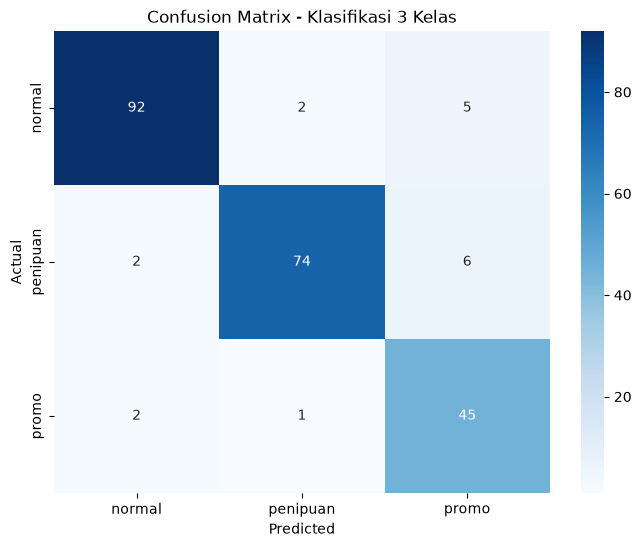

In [8]:
# Plot confusion matrix dengan label yang benar
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='g', cmap='Blues', xticklabels=['normal', 'penipuan', 'promo'],
            yticklabels=['normal', 'penipuan', 'promo'])
plt.title('Confusion Matrix - Klasifikasi 3 Kelas')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()